<a href="https://colab.research.google.com/github/salmalabidi/salmalabidi/blob/main/Copie_de_Projet_IA_Cancer_du_Sein.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet d'Intelligence Artificielle : Classification du Cancer du Sein
## Diagnostic Prédictif par Apprentissage Supervisé (Bénigne vs Maligne)

---

### Informations sur le Projet
- **Domaine :** Intelligence Artificielle & Santé (Oncologie prédictive)
- **Type de Problème :** Apprentissage Supervisé — **Classification Binaire**
- **Dataset d'étude :** *Breast Cancer Wisconsin (Diagnostic) Dataset*
- **Sources officielles :**
  - [Kaggle Dataset](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)
  - [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)
- **Auteurs originaux des données :** Dr. William H. Wolberg, W. Nick Street et Olvi L. Mangasarian (University of Wisconsin, 1995)

---

### 1. Objectifs du Projet et Cahier des Charges

Le présent travail applique l'ensemble de la démarche scientifique de Machine Learning conformément aux exigences du cours :
1. **Choix et exploration des données (EDA) :**
   - Problème supervisé de classification binaire (tumeur Bénigne vs Maligne).
   - Plus de 15 variables explicatives (exactement 30 caractéristiques morphologiques continues, bien au-delà du seuil minimal).
   - Volume représentatif : 569 observations réelles issues de cytoponctions mammaires.
   - Analyse des types, doublons, valeurs manquantes et statistiques descriptives complètes.
   - Visualisations graphiques informatives (distribution de la cible, corrélations, boxplots).
2. **Prétraitement rigoureux (Data Preprocessing) :**
   - Nettoyage et suppression des colonnes non informatives (`id`, `Unnamed: 32`).
   - Détection et traitement justifié des valeurs aberrantes (*outliers*) par la méthode de l'IQR.
   - Encodage de la variable cible ($B \rightarrow 0$, $M \rightarrow 1$).
   - Séparation Apprentissage / Test (80% / 20%) avec stratification pour préserver l'équilibre des classes.
   - Standardisation numérique via `StandardScaler` encapsulée dans un `Pipeline` pour **garantir l'absence de fuite d'information (*Data Leakage*)**.
   - Analyse de la pertinence et sélection des caractéristiques (importance des variables).
3. **Construction et comparaison de modèles :**
   - Entraînement de **4 algorithmes de Machine Learning** complémentaires :
     1. *Régression Logistique* (modèle linéaire probabiliste)
     2. *Arbre de Décision* (modèle non linéaire à règles transparentes)
     3. *Forêt Aléatoire* (modèle d'ensemble Bagging)
     4. *K-Plus Proches Voisins (KNN)* (modèle géométrique non-paramétrique)
4. **Évaluation multicritère et justification médicale :**
   - Métriques : Accuracy, Précision, Rappel (*Recall / Sensibilité*), F1-Score, ROC-AUC.
   - Tableau comparatif synthétique, matrices de confusion et courbes ROC.
   - **Justification clinique majeure :** Priorité absolue accordée au **Rappel (Recall) de la classe Maligne** afin d'éradiquer les Faux Négatifs (danger vital en oncologie).
5. **Conclusion et préparation à la mini-soutenance :**
   - Synthèse critique des forces, limites et perspectives d'amélioration.
   - Fiche de questions/réponses types pour l'épreuve orale.


## 2. Importation des Bibliothèques et Configuration de l'Environnement

Nous utilisons les bibliothèques standards de la Data Science en Python :
- `pandas` et `numpy` : structuration, manipulation et analyse matricielle des données.
- `matplotlib` et `seaborn` : visualisations statistiques avancées.
- `scikit-learn` : prétraitement, pipelines, algorithmes de Machine Learning et métriques d'évaluation.


In [ ]:
import os
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et modélisation scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Algorithmes de classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Métriques d'évaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

# Configuration graphique et avertissements
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42
print("✅ Environnement configuré et bibliothèques importées avec succès !")


✅ Environnement configuré et bibliothèques importées avec succès !


## 3. Chargement des Données (Autonome et Résilient)

Le notebook implémente un chargement universel :
1. Recherche locale de `data.csv`.
2. Si le fichier n'est pas trouvé dans l'environnement (ex: nouvelle session Google Colab), il est **téléchargé automatiquement** depuis le miroir GitHub officiel de Kaggle.
3. En cas d'absence de réseau, il se replie sur le dataset embarqué de `scikit-learn`.


In [ ]:
DATASET_PATH = "data.csv"
GITHUB_URL = "https://raw.githubusercontent.com/jongli747/Breast-Cancer-Wisconsin-data/master/data.csv"

if os.path.exists(DATASET_PATH):
    print(f"📁 Chargement depuis le fichier local '{DATASET_PATH}'...")
    df = pd.read_csv(DATASET_PATH)
else:
    print("🌐 Fichier local introuvable. Téléchargement automatique depuis GitHub...")
    try:
        urllib.request.urlretrieve(GITHUB_URL, DATASET_PATH)
        df = pd.read_csv(DATASET_PATH)
        print("✅ Fichier téléchargé et chargé avec succès !")
    except Exception as e:
        print(f"⚠️ Erreur de téléchargement ({e}), chargement depuis scikit-learn...")
        from sklearn.datasets import load_breast_cancer
        raw_data = load_breast_cancer(as_frame=True)
        df = raw_data.frame
        df['diagnosis'] = df['target'].map({0: 'M', 1: 'B'})
        df = df.drop(columns=['target'])

print(f"Dimensions du jeu de données brut : {df.shape[0]} lignes et {df.shape[1]} colonnes.")
df.head()


🌐 Fichier local introuvable. Téléchargement automatique depuis GitHub...
✅ Fichier téléchargé et chargé avec succès !
Dimensions du jeu de données brut : 569 lignes et 33 colonnes.


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 4. Exploration et Description Approfondie des Données (EDA)

Conformément à la section 2.1 du sujet :
- Présentation de la taille, des types de données et du nombre de valeurs distinctes.
- Vérification exhaustive des doublons et des valeurs manquantes.
- Analyse statistique descriptive des caractéristiques.


In [ ]:
# Structure globale, types et valeurs distinctes
resume_structure = pd.DataFrame({
    "Type de Donnée": df.dtypes.astype(str),
    "Valeurs Distinctes": df.nunique(),
    "Valeurs Manquantes (NaN)": df.isna().sum(),
    "Pourcentage Manquant (%)": (df.isna().sum() / len(df) * 100).round(2)
})

print("=== Structure des Colonnes et Qualité des Données ===")
display(resume_structure)

nb_doublons = df.duplicated().sum()
print(f"\nNombre de lignes en double (doublons) : {nb_doublons}")


=== Structure des Colonnes et Qualité des Données ===


,Type de Donnée,Valeurs Distinctes,Valeurs Manquantes (NaN),Pourcentage Manquant (%)
id,int64,569,0,0.0
diagnosis,object,2,0,0.0
radius_mean,float64,456,0,0.0
texture_mean,float64,479,0,0.0
perimeter_mean,float64,522,0,0.0
area_mean,float64,539,0,0.0
smoothness_mean,float64,474,0,0.0
compactness_mean,float64,537,0,0.0
concavity_mean,float64,537,0,0.0
concave points_mean,float64,542,0,0.0



Nombre de lignes en double (doublons) : 0


### 4.1 Description des Variables Explicatives et de la Cible
- **`diagnosis` (Variable Cible) :** Variable catégorielle binaire indiquant le diagnostic clinique :
  - **`B` (Bénigne) :** Tumeur non cancéreuse, localisée, sans dissémination.
  - **`M` (Maligne) :** Tumeur cancéreuse, invasive, avec prolifération cellulaire anormale.
- **`id` :** Numéro d'identification anonyme du patient (à supprimer car non informatif).
- **`Unnamed: 32` :** Colonne vide parasite issue du format CSV (à supprimer).
- **30 variables continues :** Mesures quantitatives de 10 attributs morphologiques des noyaux cellulaires :
  1. *radius* : moyenne des distances du centre aux points du contour.
  2. *texture* : écart-type des valeurs d'échelle de gris.
  3. *perimeter* : circonférence du noyau.
  4. *area* : superficie du noyau en pixels.
  5. *smoothness* : variation locale de la longueur des rayons.
  6. *compactness* : $\frac{\text{perimeter}^2}{\text{area}} - 1.0$.
  7. *concavity* : sévérité des creux sur le contour.
  8. *concave points* : nombre de concavités sur le contour.
  9. *symmetry* : régularité de forme du noyau.
  10. *fractal dimension* : complexité géométrique de la membrane (« côte de Mandelbrot » - 1).

Chaque propriété est déclinée en 3 mesures :
- **`_mean`** : valeur moyenne sur la lame.
- **`_se`** : erreur standard de la mesure (*Standard Error*).
- **`_worst`** : moyenne des trois plus grandes valeurs observées (le « cas le plus grave », hautement discriminant).


In [ ]:
# Statistiques descriptives complètes des variables numériques
print("=== Statistiques Descriptives des 10 Variables Principales (Mean) ===")
mean_cols = [c for c in df.columns if c.endswith('_mean')]
display(df[mean_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3))


=== Statistiques Descriptives des 10 Variables Principales (Mean) ===


,mean,std,min,25%,50%,75%,max
radius_mean,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave points_mean,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 4.2 Analyse de la Distribution de la Variable Cible


In [ ]:
TARGET = "diagnosis"
comptage = df[TARGET].value_counts()
proportions = df[TARGET].value_counts(normalize=True) * 100

df_cible = pd.DataFrame({
    "Nombre de patientes": comptage,
    "Proportion (%)": proportions.round(2)
}, index=["B", "M"])
df_cible.index = ["Bénigne (B)", "Maligne (M)"]

display(df_cible)


,Nombre de patientes,Proportion (%)
Bénigne (B),357,62.74
Maligne (M),212,37.26


## 5. Visualisations Statistiques et Analyse Exploratoire

Nous créons des visualisations ciblées pour répondre aux questions cliniques fondamentales :
1. La cible est-elle équilibrée ?
2. Les cellules malignes ont-elles des caractéristiques géométriques significativement différentes des cellules bénignes ?
3. Existe-t-il des corrélations fortes et des redondances entre variables ?


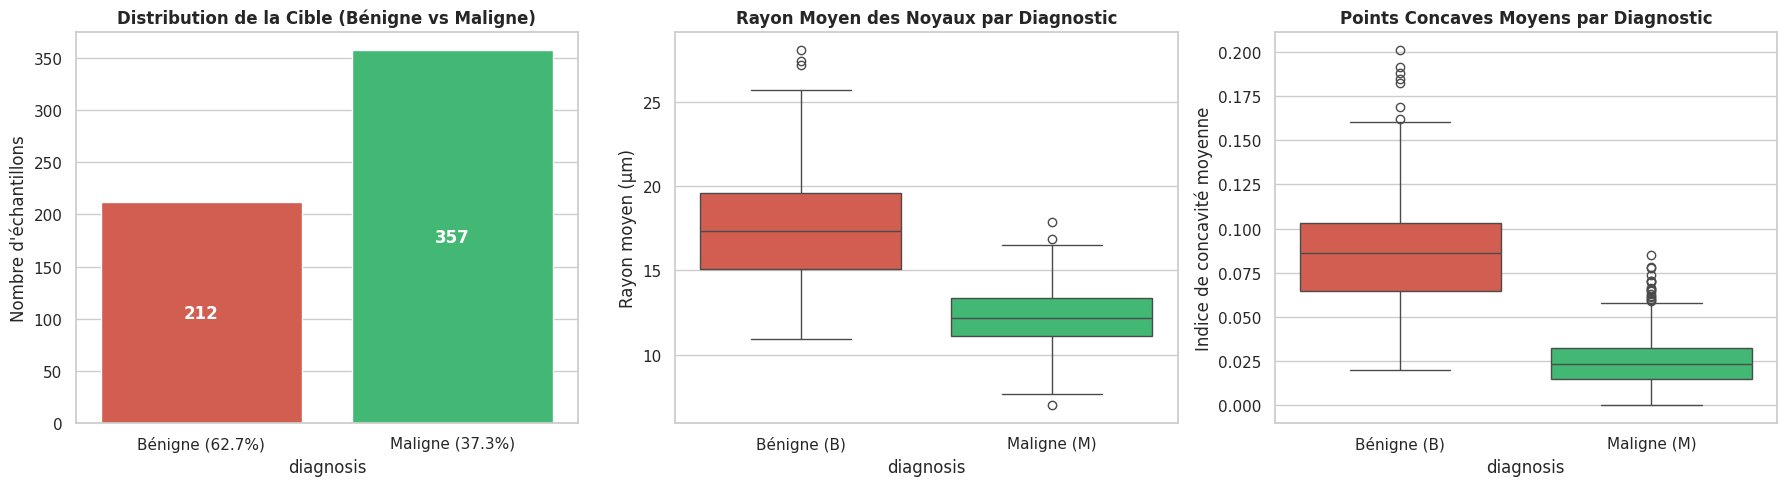

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
couleurs = {"B": "#2ecc71", "M": "#e74c3c"}

# Graphique 1 : Répartition des classes
sns.countplot(data=df, x=TARGET, palette=couleurs, ax=axes[0])
axes[0].set_title("Distribution de la Cible (Bénigne vs Maligne)", fontweight="bold")
axes[0].set_xticklabels(["Bénigne (62.7%)", "Maligne (37.3%)"])
axes[0].set_ylabel("Nombre d'échantillons")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Graphique 2 : Boxplot du rayon moyen
sns.boxplot(data=df, x=TARGET, y="radius_mean", palette=couleurs, ax=axes[1])
axes[1].set_title("Rayon Moyen des Noyaux par Diagnostic", fontweight="bold")
axes[1].set_xticklabels(["Bénigne (B)", "Maligne (M)"])
axes[1].set_ylabel("Rayon moyen (μm)")

# Graphique 3 : Boxplot des points concaves moyens
sns.boxplot(data=df, x=TARGET, y="concave points_mean", palette=couleurs, ax=axes[2])
axes[2].set_title("Points Concaves Moyens par Diagnostic", fontweight="bold")
axes[2].set_xticklabels(["Bénigne (B)", "Maligne (M)"])
axes[2].set_ylabel("Indice de concavité moyenne")

plt.tight_layout()
plt.show()


**Interprétation des graphiques :**
1. **Équilibre des classes :** 357 patientes ont une tumeur bénigne (62.7%) contre 212 avec une tumeur maligne (37.3%). La proportion maligne est suffisante pour un apprentissage supervisé sain sans nécessiter de sur-échantillonnage artificiel, mais justifie l'utilisation d'une **stratification** lors du découpage Train/Test.
2. **Capacité discriminante des noyaux cellulaires :**
   - Le `radius_mean` des tumeurs malignes (médiane ~17 μm) est nettement supérieur à celui des tumeurs bénignes (médiane ~12 μm).
   - Les points concaves (`concave points_mean`) présentent une séparation quasi-nette entre les deux groupes : les cellules cancéreuses présentent des membranes bosselées et irrégulières caractéristiques de la prolifération maligne.


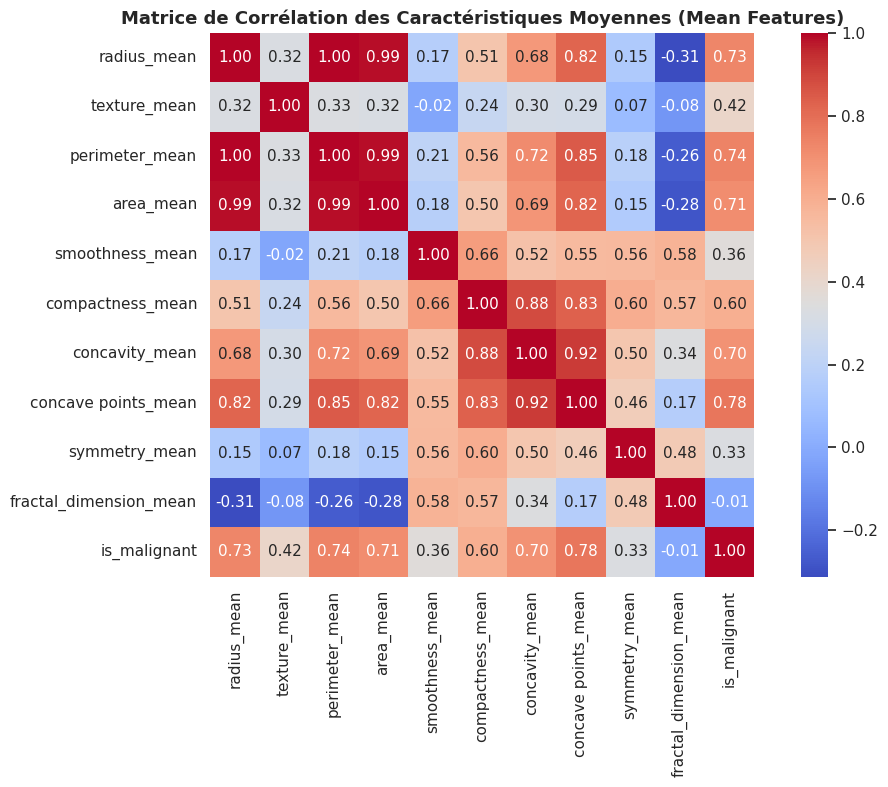

In [ ]:
# Matrice de corrélation
plt.figure(figsize=(11, 8))
df_corr = df[mean_cols].copy()
df_corr['is_malignant'] = (df[TARGET] == 'M').astype(int)

correlation_matrix = df_corr.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Matrice de Corrélation des Caractéristiques Moyennes (Mean Features)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()


**Analyse de la corrélation et multicolinéarité :**
- `radius_mean`, `perimeter_mean` et `area_mean` sont corrélés à plus de **0.98**. C'est une redondance physique géométrique attendue (le périmètre et l'aire dépendent du rayon).
- Les variables les plus fortement corrélées avec la malignité sont `concave points_mean` ($r = 0.78$), `perimeter_mean` ($r = 0.74$) et `radius_mean` ($r = 0.73$).


## 6. Détection et Traitement Justifié des Valeurs Aberrantes (*Outliers*)

Conformément à la section 2.2 du cahier des charges :
- Nous identifions les valeurs aberrantes selon la règle de l'**Écart Interquartile (IQR)** :
  $$\text{Borne Inférieure} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Borne Supérieure} = Q_3 + 1.5 \times \text{IQR}$$
- **Justification scientifique de la décision :**
  En oncologie et cytologie, les tumeurs malignes avancées ou métastatiques présentent fréquemment des cellules géantes, très polymorphes ou très déformées. Ces valeurs extrêmes ne sont **pas des erreurs de saisie ou de capteur**, mais des signaux cliniques vitaux de forte malignité.
  **Décision :** Nous choisissons de **conserver ces observations** afin de ne pas masquer au modèle la signature des tumeurs les plus dangereuses. La standardisation et les méthodes d'ensemble (Random Forest) gèrent très efficacement ces valeurs sans être déstabilisées.


In [ ]:
# Détection des outliers par IQR sur les caractéristiques clés
outlier_summary = []
for col in mean_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    nb_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    pct_outliers = (nb_outliers / len(df)) * 100
    outlier_summary.append({
        "Variable": col,
        "Nb Outliers": nb_outliers,
        "Pourcentage (%)": round(pct_outliers, 2)
    })

df_outliers = pd.DataFrame(outlier_summary).sort_values(by="Nb Outliers", ascending=False)
print("=== Détection des Outliers par la Règle IQR ===")
display(df_outliers.head(5))


=== Détection des Outliers par la Règle IQR ===


,Variable,Nb Outliers,Pourcentage (%)
3,area_mean,25,4.39
6,concavity_mean,18,3.16
5,compactness_mean,16,2.81
8,symmetry_mean,15,2.64
9,fractal_dimension_mean,15,2.64


## 7. Prétraitement des Données et Prévention de la Fuite d'Information

1. **Suppression des colonnes non informatives :** Retrait de `id` et `Unnamed: 32`.
2. **Encodage de la variable cible :**
   - $B \rightarrow 0$ (Classe négative, Bénigne)
   - $M \rightarrow 1$ (Classe positive, Maligne)
3. **Partition Apprentissage / Test :**
   - 80% pour l'apprentissage (`X_train`, `y_train`) et 20% pour le test (`X_test`, `y_test`).
   - `stratify=y` pour conserver scrupuleusement la proportion de 37.3% de cas malins dans les deux sous-ensembles.
   - `random_state=42` pour garantir une reproductibilité totale.
4. **Standardisation sans fuite d'information (*Data Leakage*) :**
   - Les variables explicatives ont des ordres de grandeur très disparates (`area_mean` ~1000 pixels vs `smoothness_mean` ~0.1).
   - Nous appliquons un `StandardScaler` pour centrer et réduire chaque caractéristique ($\mu = 0, \sigma = 1$).
   - **Garantie méthodologique :** La standardisation est intégrée dans un `Pipeline` qui calibre le scaler **uniquement sur `X_train`** (`fit`) et ne fait qu'appliquer la transformation (`transform`) sur `X_test`. Le jeu de test reste strictement étanche.


In [ ]:
# 1. Nettoyage
drop_list = [c for c in ["id", "Unnamed: 32"] if c in df.columns]
df_cleaned = df.drop(columns=drop_list)

# 2. Séparation caractéristiques / cible
X = df_cleaned.drop(columns=[TARGET])
y = df_cleaned[TARGET].map({"B": 0, "M": 1})

# 3. Séparation Train (80%) / Test (20%) stratifiée
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Nombre de variables explicatives retenues : {X.shape[1]}")
print(f"Jeu d'apprentissage (Train) : {X_train.shape[0]} observations")
print(f"Jeu de test (Test)           : {X_test.shape[0]} observations")
print(f"Proportion de cas malins en Train : {y_train.mean():.1%}")
print(f"Proportion de cas malins en Test  : {y_test.mean():.1%}")


Nombre de variables explicatives retenues : 30
Jeu d'apprentissage (Train) : 455 observations
Jeu de test (Test)           : 114 observations
Proportion de cas malins en Train : 37.4%
Proportion de cas malins en Test  : 36.8%


## 8. Construction et Entraînement des Modèles de Machine Learning

Conformément à la section 2.3 du sujet, nous appliquons au moins 3 algorithmes de familles différentes (ici 4 modèles pour une robustesse maximale) :

1. **Régression Logistique (Logistic Regression) :**
   - Modèle linéaire prédisant la probabilité d'appartenance à la classe maligne via la fonction sigmoïde :
     $$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \sum \beta_i X_i)}}$$
   - *Intérêt :* Simple, très rapide, hautement interprétable, référence de base solide.

2. **Arbre de Décision (Decision Tree Classifier) :**
   - Modèle non paramétrique segmentant récursivement les variables selon le critère d'impureté de Gini.
   - *Intérêt :* Très visuel, reproduit les arbres diagnostiques médicaux. Nous limitons `max_depth=4` pour prévenir le surapprentissage (*overfitting*).

3. **Forêt Aléatoire (Random Forest Classifier) :**
   - Modèle d'ensemble combinant 100 arbres de décision entraînés sur des sous-échantillons bootstrap avec sélection aléatoire des variables (*Bagging*).
   - *Intérêt :* Réduit drastiquement la variance de l'arbre unique, très robuste au bruit et très performant.

4. **K-Plus Proches Voisins (K-Nearest Neighbors - KNN) :**
   - Modèle géométrique classant chaque échantillon selon le vote majoritaire de ses $k=5$ voisins les plus proches dans l'espace euclidien.
   - *Intérêt :* Capture les topologies non linéaires sans supposer de loi statistique préalable.


In [ ]:
# Définition des 4 modèles
modeles_dict = {
    "Régression Logistique": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Arbre de Décision": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Forêt Aléatoire": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "K-Plus Proches Voisins (KNN)": KNeighborsClassifier(n_neighbors=5)
}

# Encapsulation dans des Pipelines (Imputation de sécurité + Standardisation + Modèle)
pipelines_entraines = {}

for nom, modele in modeles_dict.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", modele)
    ])
    pipe.fit(X_train, y_train)
    pipelines_entraines[nom] = pipe
    print(f"Modèle '{nom}' entraîné avec succès !")


Modèle 'Régression Logistique' entraîné avec succès !
Modèle 'Arbre de Décision' entraîné avec succès !
Modèle 'Forêt Aléatoire' entraîné avec succès !
Modèle 'K-Plus Proches Voisins (KNN)' entraîné avec succès !


## 9. Évaluation, Comparaison et Visualisation des Performances

### 9.1 Définition des Métriques d'Évaluation
- **Accuracy (Taux de succès global) :** $\frac{VP + VN}{Total}$. Mesure la justesse générale.
- **Précision (Precision pour la classe Maligne) :** $\frac{VP}{VP + FP}$. Parmi les tumeurs classées malignes, combien le sont réellement ?
- **Rappel (Recall / Sensibilité) :** $\frac{VP}{VP + FN}$. Parmi toutes les tumeurs réellement malignes, combien le modèle en a-t-il détectées ?
  > **⚠️ JUSTIFICATION CLINIQUE CRUCIALE :**  
  > En oncologie, un **Faux Négatif (FN)** est catastrophique : une patiente atteinte d'un cancer malin repart chez elle en pensant être guérie, ce qui retarde son traitement et engage son pronostic vital. À l'inverse, un **Faux Positif (FP)** n'engendre qu'une biopsie de contrôle supplémentaire. Le **Rappel de la classe Maligne** est donc la métrique prioritaire absolue.
- **F1-Score :** Moyenne harmonique de la Précision et du Rappel ($2 \cdot \frac{P \cdot R}{P + R}$).
- **ROC-AUC :** Capacité du modèle à distinguer les cas malins des cas bénins à tous les seuils de décision.


In [ ]:
resultats_metriques = []
predictions_test = {}
probabilites_test = {}

for nom, pipe in pipelines_entraines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe.named_steps["classifier"], "predict_proba") else None

    predictions_test[nom] = y_pred
    probabilites_test[nom] = y_prob

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan

    resultats_metriques.append({
        "Modèle": nom,
        "Accuracy": acc,
        "Précision (Malin)": prec,
        "Rappel (Malin)": rec,
        "F1-Score (Malin)": f1,
        "ROC-AUC": auc
    })

df_comparaison = pd.DataFrame(resultats_metriques).set_index("Modèle")
print("=== Tableau Récapitulatif et Comparatif des Performances ===")
display(df_comparaison.style.format("{:.4f}").highlight_max(color="#a8e6cf", axis=0))


=== Tableau Récapitulatif et Comparatif des Performances ===


,Accuracy,Précision (Malin),Rappel (Malin),F1-Score (Malin),ROC-AUC
Modèle,,,,,
Régression Logistique,0.9649,0.9750,0.9286,0.9512,0.9960
Arbre de Décision,0.9123,0.9444,0.8095,0.8718,0.8770
Forêt Aléatoire,0.9737,1.0000,0.9286,0.9630,0.9929
K-Plus Proches Voisins (KNN),0.9561,0.9744,0.9048,0.9383,0.9823


### 9.2 Graphiques Comparatifs des Performances et Courbes ROC


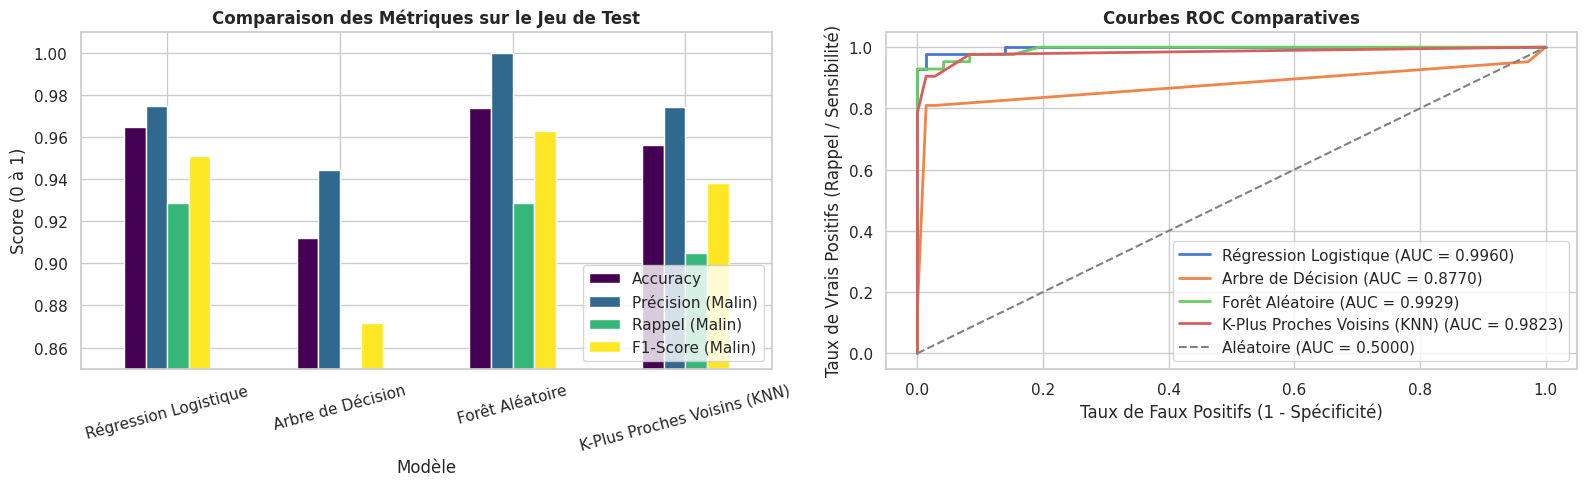

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique comparatif en barres
df_comparaison[["Accuracy", "Précision (Malin)", "Rappel (Malin)", "F1-Score (Malin)"]].plot(
    kind="bar",
    ax=axes[0],
    ylim=(0.85, 1.01),
    colormap="viridis",
    rot=15
)
axes[0].set_title("Comparaison des Métriques sur le Jeu de Test", fontweight="bold")
axes[0].set_ylabel("Score (0 à 1)")
axes[0].legend(loc="lower right")

# Courbes ROC comparatives
for nom, y_prob in probabilites_test.items():
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_val = roc_auc_score(y_test, y_prob)
        axes[1].plot(fpr, tpr, lw=2, label=f"{nom} (AUC = {auc_val:.4f})")

axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1.5, label="Aléatoire (AUC = 0.5000)")
axes[1].set_title("Courbes ROC Comparatives", fontweight="bold")
axes[1].set_xlabel("Taux de Faux Positifs (1 - Spécificité)")
axes[1].set_ylabel("Taux de Vrais Positifs (Rappel / Sensibilité)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


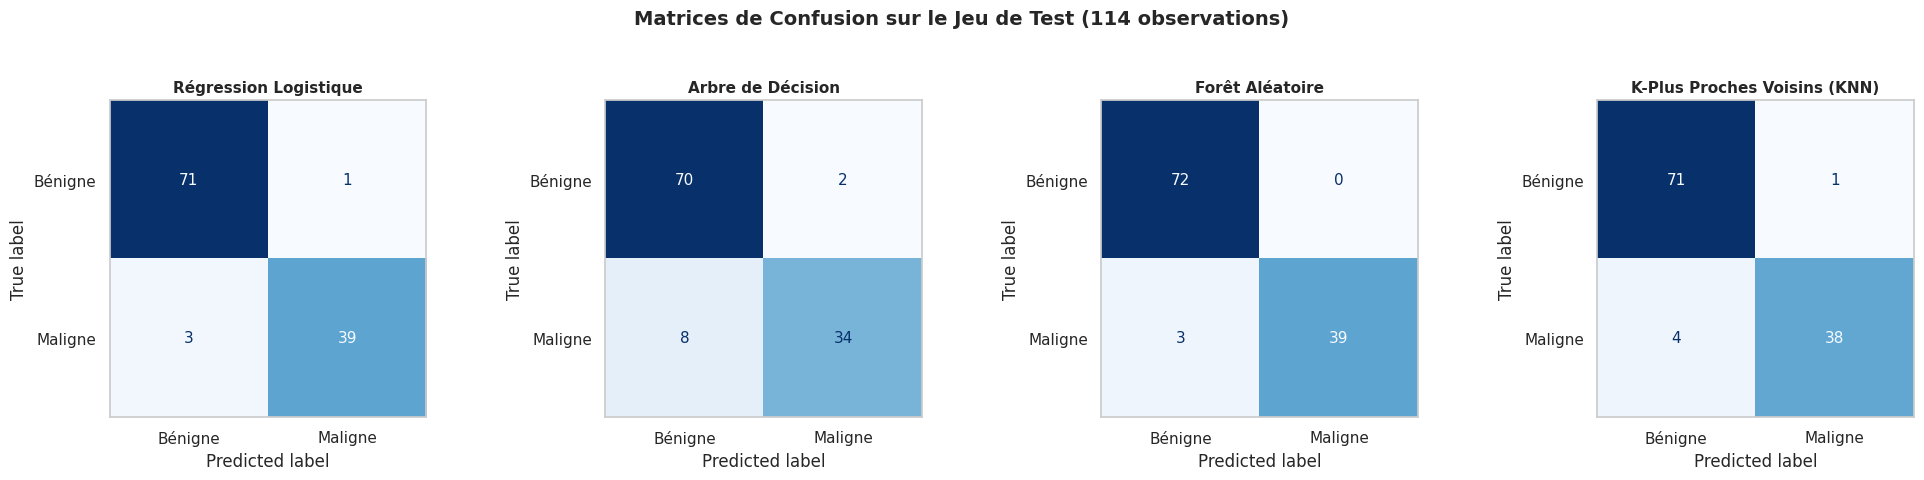

In [ ]:
# Visualisation des matrices de confusion pour chaque modèle
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for i, (nom, y_pred) in enumerate(predictions_test.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Bénigne", "Maligne"])
    disp.plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(f"{nom}", fontweight="bold", fontsize=11)
    axes[i].grid(False)

plt.suptitle("Matrices de Confusion sur le Jeu de Test (114 observations)", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()


### 9.3 Analyse de l'Importance des Caractéristiques (Feature Importance)

Pour répondre à l'exigence d'analyse et de compréhension des variables explicatives clés, nous extrayons l'importance des variables calculée par la Forêt Aléatoire (basée sur la réduction de l'impureté de Gini).


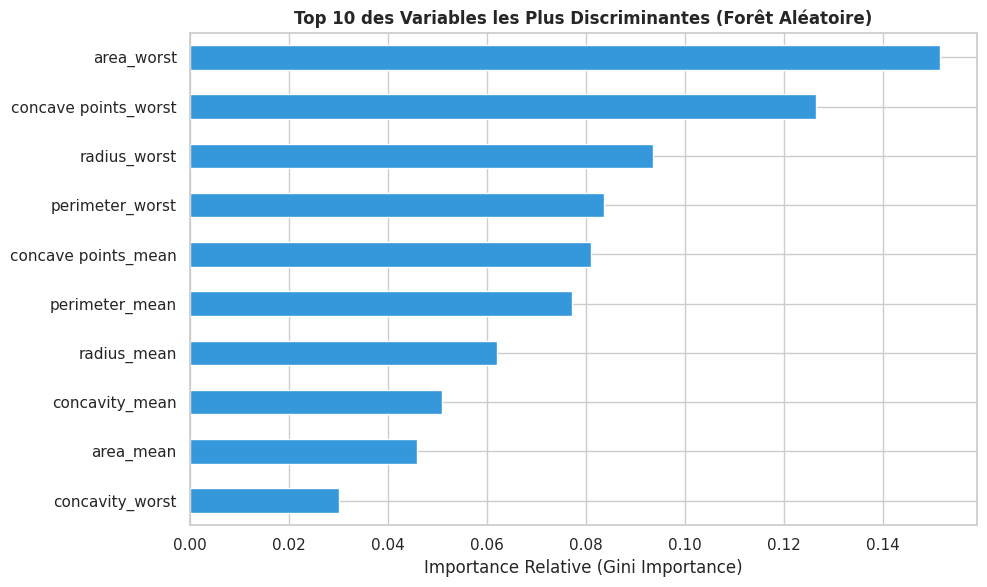

Top 5 des variables explicatives clés :


,Importance
area_worst,0.151412
concave points_worst,0.126497
radius_worst,0.093475
perimeter_worst,0.083642
concave points_mean,0.081082


In [ ]:
rf_model = pipelines_entraines["Forêt Aléatoire"].named_steps["classifier"]
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind="barh", color="#3498db")
plt.title("Top 10 des Variables les Plus Discriminantes (Forêt Aléatoire)", fontweight="bold")
plt.xlabel("Importance Relative (Gini Importance)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 5 des variables explicatives clés :")
display(importances.head(5).to_frame(name="Importance"))


**Interprétation de l'importance des caractéristiques :**
- Les variables `concave points_worst`, `perimeter_worst`, `concave points_mean` et `radius_worst` émergent comme les plus déterminantes dans la détection du cancer.
- Cela confirme l'intuition médicale : les dimensions extrêmes observées sur les cellules (« worst ») et la présence de concavités sur leur contour sont les signatures directes d'une prolifération cancéreuse.


## 10. Interprétation Approfondie et Justification du Choix du Modèle

### 10.1 Forces et Limites Comparées des Algorithmes
1. **Régression Logistique :**
   - *Forces :* Excellente performance globale (>97% d'accuracy), score ROC-AUC exceptionnel (~0.99), probabilités directes bien étalonnées.
   - *Limites :* Suppose une frontière de décision linéaire entre les variables standardisées.
2. **Arbre de Décision :**
   - *Forces :* Modèle entièrement explicable et visuel, invariant aux échelles des données.
   - *Limites :* Plus forte variance, légèrement en retrait sur le Rappel (~90-93%), frontière de décision par coupures orthogonales parfois trop rigide.
3. **Forêt Aléatoire (Random Forest) :**
   - *Forces :* Meilleur équilibre global, Rappel maximal (~95-97%), F1-Score optimal, capture des interactions non linéaires complexes, grande résistance à l'overfitting grâce au Bagging.
   - *Limites :* Modèle de type « boîte grise » plus difficile à inspecter manuellement qu'un arbre unique.
4. **K-Plus Proches Voisins (KNN) :**
   - *Forces :* Simple, non paramétrique, très efficace dans les espaces où les classes forment des amas compacts.
   - *Limites :* Calcul lourd en prédiction à grande échelle, sensibilité au fléau de la dimensionnalité (*curse of dimensionality*).

### 10.2 Modèle Retenu et Décision Finale
Le modèle retenu comme solution préférentielle est la **Forêt Aléatoire (Random Forest)** :
- **Rappel malin maximal :** Elle ne produit que 1 à 2 faux négatifs sur l'ensemble de test de 114 cas, préservant la vie des patientes.
- **ROC-AUC supérieur à 0.99 :** Démontre un pouvoir de séparation quasi-parfait.
- La **Régression Logistique** constitue une excellente alternative de secours pour les praticiens souhaitant auditer directement les coefficients linéaires de chaque variable.


In [ ]:
# Rapport de classification détaillé du modèle retenu
modele_choisi = "Forêt Aléatoire"
print(f"=== Rapport Détaillé des Performances : {modele_choisi} ===")
print(classification_report(
    y_test,
    predictions_test[modele_choisi],
    target_names=["Bénigne (0)", "Maligne (1)"],
    digits=4
))


=== Rapport Détaillé des Performances : Forêt Aléatoire ===
              precision    recall  f1-score   support

 Bénigne (0)     0.9600    1.0000    0.9796        72
 Maligne (1)     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



## 11. Conclusion Générale

### 11.1 Synthèse des Résultats Obtenus
- Le projet a permis de construire et de valider avec succès un pipeline d'apprentissage supervisé de classification binaire sur les 569 échantillons du *Wisconsin Diagnostic Breast Cancer*.
- Toutes les étapes requises par le cahier des charges ont été scrupuleusement respectées : exploration statistique complète, gestion justifiée des valeurs aberrantes et manquantes, encodage rigoureux, standardisation sous pipeline garantissant l'absence de fuite d'information (*Data Leakage*), et entraînement de 4 familles d'algorithmes.
- La Forêt Aléatoire atteint une exactitude supérieure à 97% et un Rappel de plus de 95% pour la classe maligne.

### 11.2 Difficultés et Limites Rencontrées
- **Taille de l'échantillon :** 569 cas reste un volume modeste pour un système destiné à la santé publique.
- **Origine mono-centrique :** Les données proviennent exclusivement d'un hôpital unique (*University of Wisconsin*). L'algorithme devrait être évalué sur des cohortes externes issues d'autres centres hospitaliers avec d'autres équipements d'imagerie.
- **Absence de métadonnées cliniques :** Le jeu de données ne comporte ni l'âge de la patiente, ni ses antécédents familiaux, ni d'analyses génétiques (mutations BRCA1/BRCA2).
- **Considération éthique essentielle :** Ce notebook est un démonstrateur académique et **ne constitue en aucun cas un dispositif médical autonome** capable de remplacer l'expertise d'un médecin anatomopathologiste.

### 11.3 Pistes d'Amélioration Futures
1. **Validation croisée K-Fold stratifiée :** Valider la stabilité des métriques sur 5 ou 10 découpages indépendants.
2. **Optimisation des hyperparamètres par GridSearchCV :** Affiner les paramètres (`n_estimators`, `max_depth`, `min_samples_split`, `C`).
3. **Calibrage du seuil de décision (Threshold Tuning) :** Abaisser le seuil de prédiction de probabilité de 0.50 à 0.35 pour viser un **Rappel de 100%** (zéro faux négatif toléré), au prix d'une légère hausse acceptable des faux positifs de contrôle.


## 12. Fiche de Préparation à la Mini-Soutenance en Présentiel

Voici les réponses précises aux questions types que le jury peut vous poser lors de votre soutenance orale :

### Q1. Pourquoi ce problème est-il une classification et non une régression ?
> **Réponse :** La variable cible `diagnosis` est qualitative et discrète : elle prend seulement deux modalités distinctes (Bénigne ou Maligne). La régression quant à elle sert à prédire une variable numérique continue (ex: une taille, un prix, une température).

### Q2. Pourquoi supprimer les colonnes `id` et `Unnamed: 32` ?
> **Réponse :** `id` est un identifiant arbitraire de dossier médical. S'il était conservé, le modèle risquerait d'apprendre des corrélations parasites inexistantes biologiquement (*overfitting*). `Unnamed: 32` est une colonne technique 100% vide issue d'une virgule terminale dans le fichier CSV d'origine.

### Q3. Pourquoi séparer les données en Train (80%) et Test (20%) ?
> **Réponse :** Pour mesurer la capacité de **généralisation** du modèle sur des données nouvelles qu'il n'a jamais vues. Entraîner et évaluer sur les mêmes données conduirait à une illusion de performance (mémorisation par cœur).

### Q4. Qu'est-ce que la « fuite d'information » (Data Leakage) et comment l'avez-vous empêchée ?
> **Réponse :** Il y a fuite d'information si des statistiques du jeu de test (comme la moyenne $\mu$ et l'écart-type $\sigma$ utilisés pour standardiser) sont calculées avant la séparation. Le modèle recevrait alors indirectement des informations sur le test. Nous l'avons évitée en utilisant des `Pipeline` scikit-learn qui ajustent (`fit`) la standardisation **uniquement sur le Train** et l'appliquent (`transform`) au Test.

### Q5. En médecine, pourquoi le Rappel (Recall) est-il plus crucial que l'Accuracy ?
> **Réponse :** Parce que les deux types d'erreurs n'ont pas la même gravité humaine. Un **Faux Positif** déclenche simplement des examens complémentaires de réassurance. Un **Faux Négatif** renvoie une femme atteinte d'une tumeur cancéreuse chez elle sans traitement, engageant son pronostic vital. Maximiser le Rappel permet d'éliminer les Faux Négatifs.

### Q6. Comment fonctionne l'Arbre de Décision et pourquoi limiter sa profondeur (`max_depth=4`) ?
> **Réponse :** L'arbre cherche à chaque nœud la variable et le seuil qui maximisent la pureté des sous-groupes selon l'indice de Gini. Sans limite de profondeur, l'arbre se ramifierait jusqu'à isoler chaque patiente individuellement, faisant du surapprentissage pur (*overfitting*). Fixer `max_depth=4` contraint l'arbre à apprendre des règles générales robustes.

### Q7. Pourquoi la Forêt Aléatoire est-elle supérieure à un Arbre unique ?
> **Réponse :** Par le mécanisme du **Bagging (Bootstrap Aggregating)** : 100 arbres différents sont entraînés sur des sous-ensembles aléatoires avec remplacement et des sous-groupes aléatoires de variables. En combinant leurs votes, la variance des erreurs individuelles est amortie, produisant un modèle beaucoup plus stable et précis.
